# **PROBLEM 1 (Left Tail TEST )**

#**BUSINESS PROBLEM :**


 A retail banking firm monitors customer transactions to forecast credit risk, optimize credit limit caps, and tailor promotional offers. Historically, marketing and financial models have operated under the baseline assumption that the population average spending per transaction across all active credit card accounts is $3,000.



#**THE CHALLENGE:**

Recent shifts in consumer sentiment, inflation adjustments, and competing payment alternatives suggest a noticeable downward shift in customer transaction sizes. The finance department suspects that the current true population mean transaction amount has fallen significantly below the historical $3,000 benchmark.

If this drop is statistically real, it indicates lower transactional revenue from interchange fees and requires the bank to adjust its annual revenue projections.




# H0: The average spending is at least $3,000

# Mu>=3000

# H1: The Average Spending is more than $3,000

# Mu < 3000

In [ ]:
import numpy as np
import pandas as pd
import statsmodels
from scipy.stats import norm



In [ ]:
df=pd.read_excel("credit_card_middle_class_spending.xlsx")

In [ ]:
df

,Person,Date,Expense,Gender,Amount
0,Rahul Joshi,2026-01-01,Healthcare,Male,1823
1,Vikas More,2026-01-02,Shopping,Male,4416
2,Sneha Kulkarni,2026-01-04,Fuel,Female,3078
3,Rahul Joshi,2026-01-05,Fuel,Male,4303
4,Anjali Singh,2026-01-06,Fuel,Female,2859
...,...,...,...,...,...
145,Pooja Jadhav,2026-09-19,Fuel,Female,2550
146,Sneha Kulkarni,2026-09-23,Shopping,Female,7287
147,Amit Sharma,2026-09-24,Entertainment,Male,306
148,Riya Mehta,2026-09-24,Utilities,Female,3636


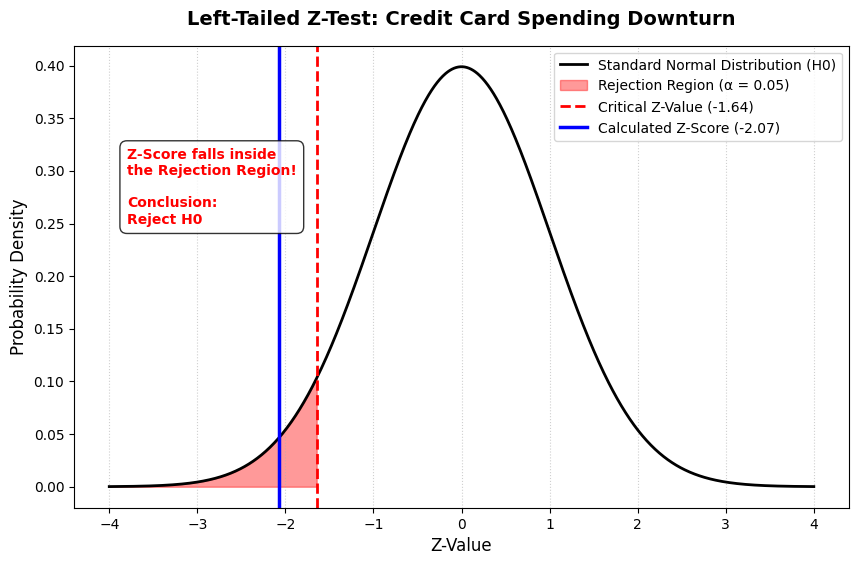

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# 1. Define inputs based on your left-tailed test metrics
z_score = -2.067131958948026
alpha = 0.05
z_critical = stats.norm.ppf(alpha)  # Will calculate ~ -1.6449

# 2. Generate data points for a standard normal curve
x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x)

# 3. Create the plot
plt.figure(figsize=(10, 6), dpi=100)
plt.plot(x, y, label='Standard Normal Distribution (H0)', color='black', lw=2)

# 4. Color the Rejection Region (Left Tail)
x_reject = np.linspace(-4, z_critical, 100)
y_reject = stats.norm.pdf(x_reject)
plt.fill_between(x_reject, y_reject, color='red', alpha=0.4, label=f'Rejection Region (α = {alpha})')

# 5. Add lines for Critical Value and Calculated Z-Score
plt.axvline(z_critical, color='red', linestyle='--', lw=2, label=f'Critical Z-Value ({z_critical:.2f})')
plt.axvline(z_score, color='blue', linestyle='-', lw=2.5, label=f'Calculated Z-Score ({z_score:.2f})')

# 6. Formatting and Titles
plt.title('Left-Tailed Z-Test: Credit Card Spending Downturn', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Z-Value', fontsize=12)
plt.ylabel('Probability Density', fontsize=12)
plt.legend(loc='upper right', fontsize=10)
plt.grid(axis='x', linestyle=':', alpha=0.6)

# Annotate Conclusion
plt.text(-3.8, 0.25, 'Z-Score falls inside\nthe Rejection Region!\n\nConclusion:\nReject H0',
         bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'), color='red', fontweight='bold')

# Save chart as image to upload to GitHub
plt.savefig('left_tail_z_test_plot.png', bbox_inches='tight')
plt.show()


In [ ]:
df.columns = df.columns.str.strip()

In [ ]:
x_bar=df["Amount"].mean()

In [ ]:
x1=df.Amount

In [ ]:
SD=df["Amount"].std()

In [ ]:
SD

1725.5099991801535

In [ ]:
df

,Person,Date,Expense,Gender,Amount
0,Rahul Joshi,2026-01-01,Healthcare,Male,1823
1,Vikas More,2026-01-02,Shopping,Male,4416
2,Sneha Kulkarni,2026-01-04,Fuel,Female,3078
3,Rahul Joshi,2026-01-05,Fuel,Male,4303
4,Anjali Singh,2026-01-06,Fuel,Female,2859
...,...,...,...,...,...
145,Pooja Jadhav,2026-09-19,Fuel,Female,2550
146,Sneha Kulkarni,2026-09-23,Shopping,Female,7287
147,Amit Sharma,2026-09-24,Entertainment,Male,306
148,Riya Mehta,2026-09-24,Utilities,Female,3636


In [ ]:
df.tail()

,Person,Date,Expense,Gender,Amount
145,Pooja Jadhav,2026-09-19,Fuel,Female,2550
146,Sneha Kulkarni,2026-09-23,Shopping,Female,7287
147,Amit Sharma,2026-09-24,Entertainment,Male,306
148,Riya Mehta,2026-09-24,Utilities,Female,3636
149,Anjali Singh,2026-09-25,Food & Dining,Female,2017


In [ ]:
n = len(df["Amount"])
print(n)

150


In [ ]:
print(df["Amount"].mean())

2708.766666666667


In [ ]:
Z = (2708.77 - 3000)/(np.std(x1,ddof=1)/150**0.5)


In [ ]:
Z


-2.0671131958948026

In [ ]:
p_value=norm.cdf(Z)
p_value

np.float64(0.019361744480310868)

In [ ]:
from statsmodels.stats.weightstats import ztest
statsmodels.stats.weightstats.ztest(x1,value=3000,alternative='smaller')



(np.float64(-2.0671368554673712), np.float64(0.019360630068965882))

In [ ]:
if(p_value<0.05):
  print("Reject the Null Hypothesis")
else:
  print("We Fail to reject the Null Hypothesis")


Reject the Null Hypothesis


 Conclusion : There is statistically significant evidence to conclude that the true population mean for customer transaction spending is less than \$3,000.

# **PROBLEM 2 (RIGHT TAIL TEST )**


# BUSINESS PROBLEM :

A credit card provider keeps a baseline assumption that its cardholders have a historical average transaction size of ₹2,500. Following a major rewards program upgrade designed to incentivize larger purchases, the product team believes that the marketing campaign was successful and that the average transaction size has now significantly increased beyond the old benchmark.



# The Challenge:


If transaction sizes have truly grown, the company will increase its credit extension limits and launch higher-tier merchant partnerships. However, if the increase isn't statistically meaningful, the rewards program update may not be yielding a high enough return on investment (ROI).



# Hypthesis

H0 :Average spending has not increased and remains less than or equal to ₹2,500.

MU <= ₹2,500

H1 :Average spending has increased and is more than ₹2,500.

MU > ₹2,500


In [ ]:
import numpy as np
import pandas as pd
import statsmodels
from scipy.stats import norm



In [ ]:
x1=pd.read_excel("credit_card_middle_class_spending.xlsx")

In [ ]:
x1

,Person,Date,Expense,Gender,Amount
0,Rahul Joshi,2026-01-01,Healthcare,Male,1823
1,Vikas More,2026-01-02,Shopping,Male,4416
2,Sneha Kulkarni,2026-01-04,Fuel,Female,3078
3,Rahul Joshi,2026-01-05,Fuel,Male,4303
4,Anjali Singh,2026-01-06,Fuel,Female,2859
...,...,...,...,...,...
145,Pooja Jadhav,2026-09-19,Fuel,Female,2550
146,Sneha Kulkarni,2026-09-23,Shopping,Female,7287
147,Amit Sharma,2026-09-24,Entertainment,Male,306
148,Riya Mehta,2026-09-24,Utilities,Female,3636


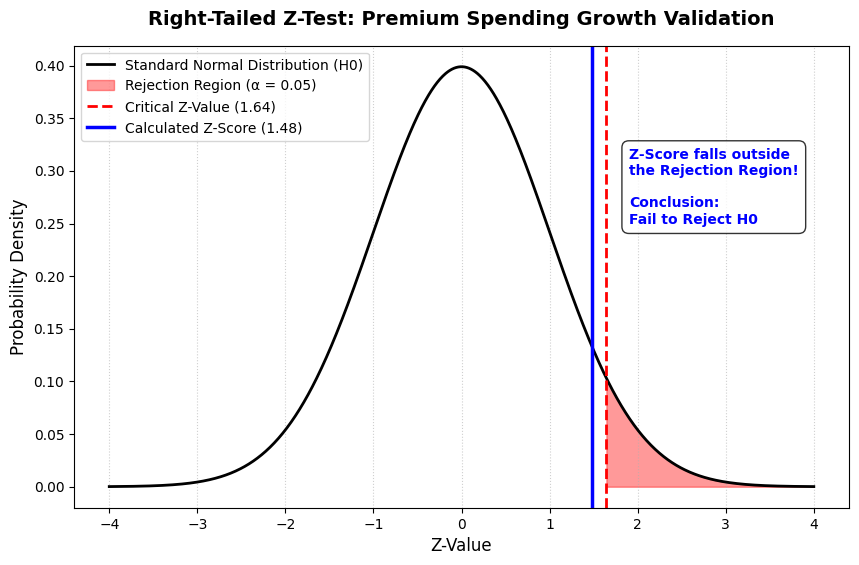

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# 1. Define inputs based on your right-tailed test metrics
z_score = 1.4817990300780781
alpha = 0.05
z_critical = stats.norm.ppf(1 - alpha)  # Will calculate ~ 1.6449

# 2. Generate data points for a standard normal curve
x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x)

# 3. Create the plot
plt.figure(figsize=(10, 6), dpi=100)
plt.plot(x, y, label='Standard Normal Distribution (H0)', color='black', lw=2)

# 4. Color the Rejection Region (Right Tail)
x_reject = np.linspace(z_critical, 4, 100)
y_reject = stats.norm.pdf(x_reject)
plt.fill_between(x_reject, y_reject, color='red', alpha=0.4, label=f'Rejection Region (α = {alpha})')

# 5. Add lines for Critical Value and Calculated Z-Score
plt.axvline(z_critical, color='red', linestyle='--', lw=2, label=f'Critical Z-Value ({z_critical:.2f})')
plt.axvline(z_score, color='blue', linestyle='-', lw=2.5, label=f'Calculated Z-Score ({z_score:.2f})')

# 6. Formatting and Titles
plt.title('Right-Tailed Z-Test: Premium Spending Growth Validation', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Z-Value', fontsize=12)
plt.ylabel('Probability Density', fontsize=12)
plt.legend(loc='upper left', fontsize=10)
plt.grid(axis='x', linestyle=':', alpha=0.6)

# Annotate Conclusion
plt.text(1.9, 0.25, 'Z-Score falls outside\nthe Rejection Region!\n\nConclusion:\nFail to Reject H0',
         bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'), color='blue', fontweight='bold')

# Save chart as image to upload to GitHub
plt.savefig('right_tail_z_test_plot.png', bbox_inches='tight')
plt.show()


In [ ]:
x_bar=np.mean(x1["Amount "])
print("Mean :",x_bar)

Mean : 2708.766666666667


In [ ]:
std=np.std(x1["Amount "],ddof=1)
print("Standard Deviation :",std)


Standard Deviation : 1725.5099991801535


In [ ]:
U=2500
alpha=0.05

In [ ]:
Z_Score=(x_bar-U)/(std/np.sqrt(len(x1)))
print(Z_Score)

1.4817990300780781


In [ ]:
p_value=1-norm.cdf(Z_Score)
print(p_value)

0.06919688863363016


In [ ]:
if(p_value<0.05):
  print("Reject the Null Hypothesis")
else:
  print("We Fail to reject the Null Hypothesis")


We Fail to reject the Null Hypothesis


# Conclusion :

There is insufficient evidence at the 95% confidence level to conclude that the population average spending has significantly increased beyond ₹2,500. The marketing and rewards teams should optimize current program terms before committing to scaling higher credit caps.